In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Some helper functions

In [3]:
def display_image(img, cmap=None):
    plt.figure(figsize=(20, 10))
    if cmap is None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.axis('off')
    plt.show()

def display_two_images(img, img2, cmap=None):
    plt.figure(figsize=(20, 10))
    plt.subplot(1, 2, 1)
    if cmap is None:
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img, cmap=cmap)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    if cmap is None:
        plt.imshow(cv2.cvtColor(img2, cv2.COLOR_BGR2RGB))
    else:
        plt.imshow(img2, cmap=cmap)
    plt.axis('off')
    plt.show()

# Loading test images

findfont: Failed to find font weight normal for Lucida Grande, now using 500.


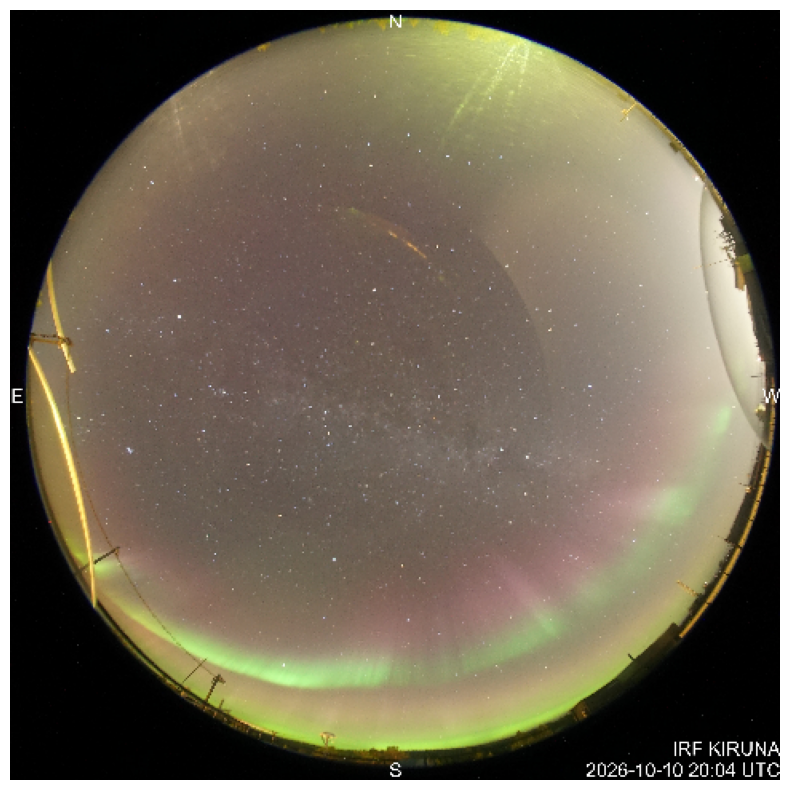

In [4]:
images = {"cloudy_no_stars": cv2.imread('images/2020-11-27T20.09.00.000KRN_small.jpeg'), 
          "clear_some_aurora": cv2.imread('images/2026-10-10T20.04.00.000KRN.jpeg'), 
          "overcast_raindrops": cv2.imread('images/2023-09-11T22.26.00.000KRN_small.jpeg'), 
          "overcast": cv2.imread('images/2023-12-14T01.52.00.000KRN_small.jpeg'), 
          "clear_aurora": cv2.imread('images/2024-10-11T22.11.00.000KRN_small.jpeg'), 
          "overcast_stars": cv2.imread('images/2024-10-25T21.02.00.000KRN_small.jpeg'), 
          "aurora_clouds_stars": cv2.imread('images/2024-10-26T21.40.00.000KRN_small.jpeg')
}

# choosing which image to test it out on
im = images['clear_some_aurora']

# resizing the image
im = cv2.resize(im, # original image
                (482,482), # set fx and fy, not the final size
                interpolation=cv2.INTER_NEAREST)
im_gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)

display_image(im)

# Image processing

## Making a defect image (reflections and unwanted elements in the picture)

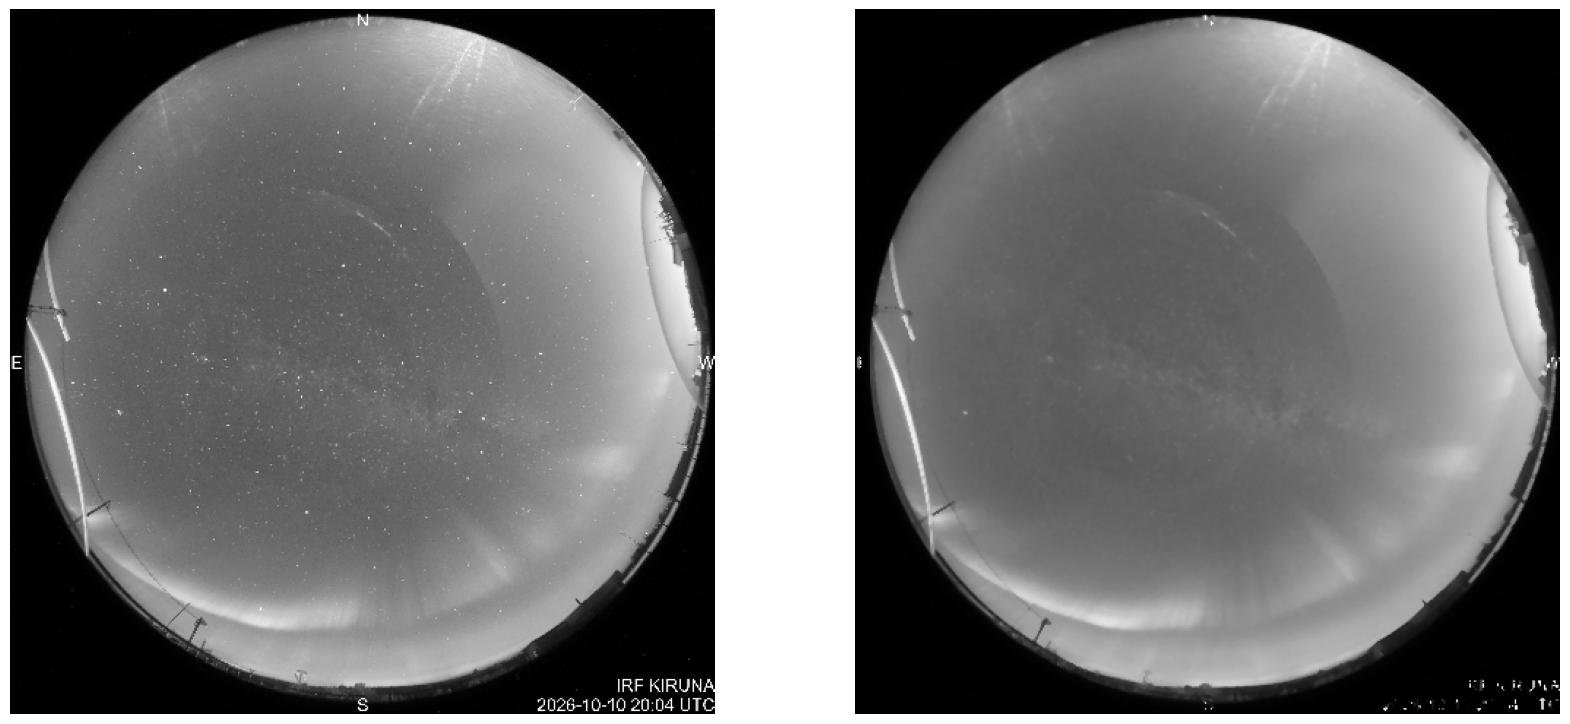

In [5]:
# blur it to "kill" off the stars
blur = cv2.medianBlur(im_gray, 3)

display_two_images(im_gray, blur)

## Subtracting it from the original image

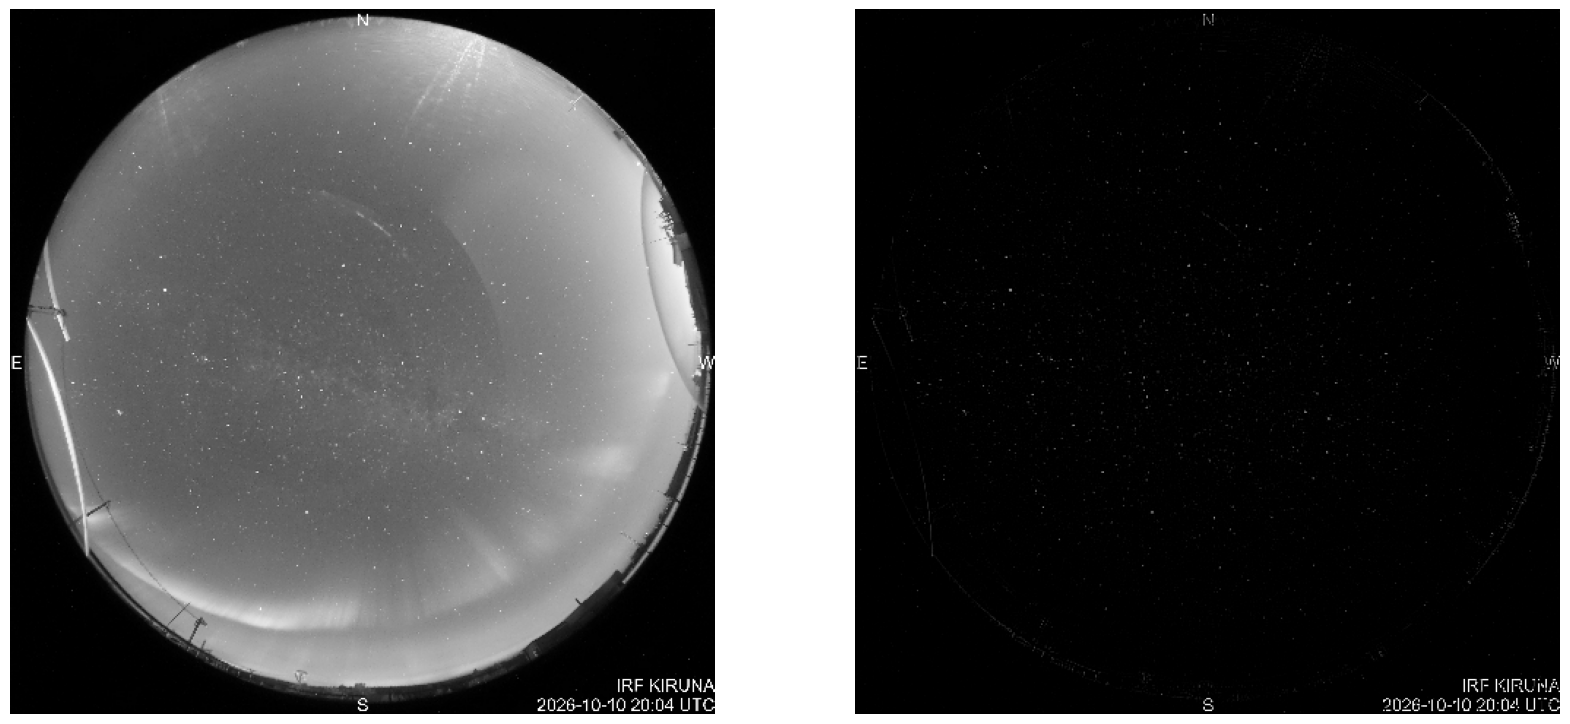

In [6]:
subtracted = cv2.subtract(im_gray, blur)
display_two_images(im_gray, subtracted)
# data is still there even though it doesn't look like it

## Extracting the brightest features from the image and defect image

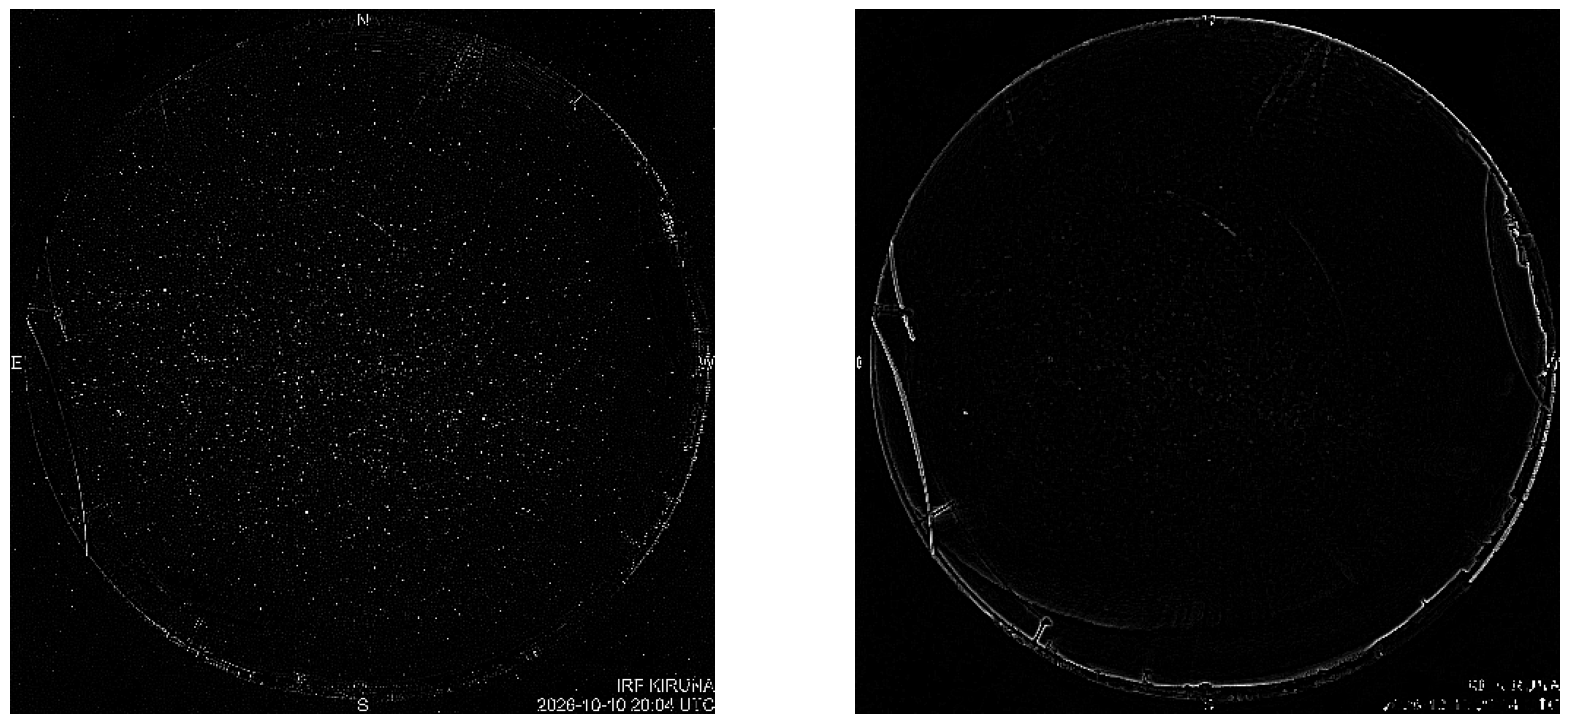

In [7]:
kernel = np.asarray([
    [-1, -1, -1],
    [-1, 8, -1],
    [-1, -1, -1]
])

features = cv2.filter2D(subtracted, ddepth=-1, kernel=kernel, anchor=(-1, -1), delta=0, borderType=cv2.BORDER_DEFAULT)
defect_features = cv2.filter2D(blur, ddepth=-1, kernel=kernel, anchor=(-1, -1), delta=0, borderType=cv2.BORDER_DEFAULT)

display_two_images(features, defect_features)

## Masking only the central portion of the pictures

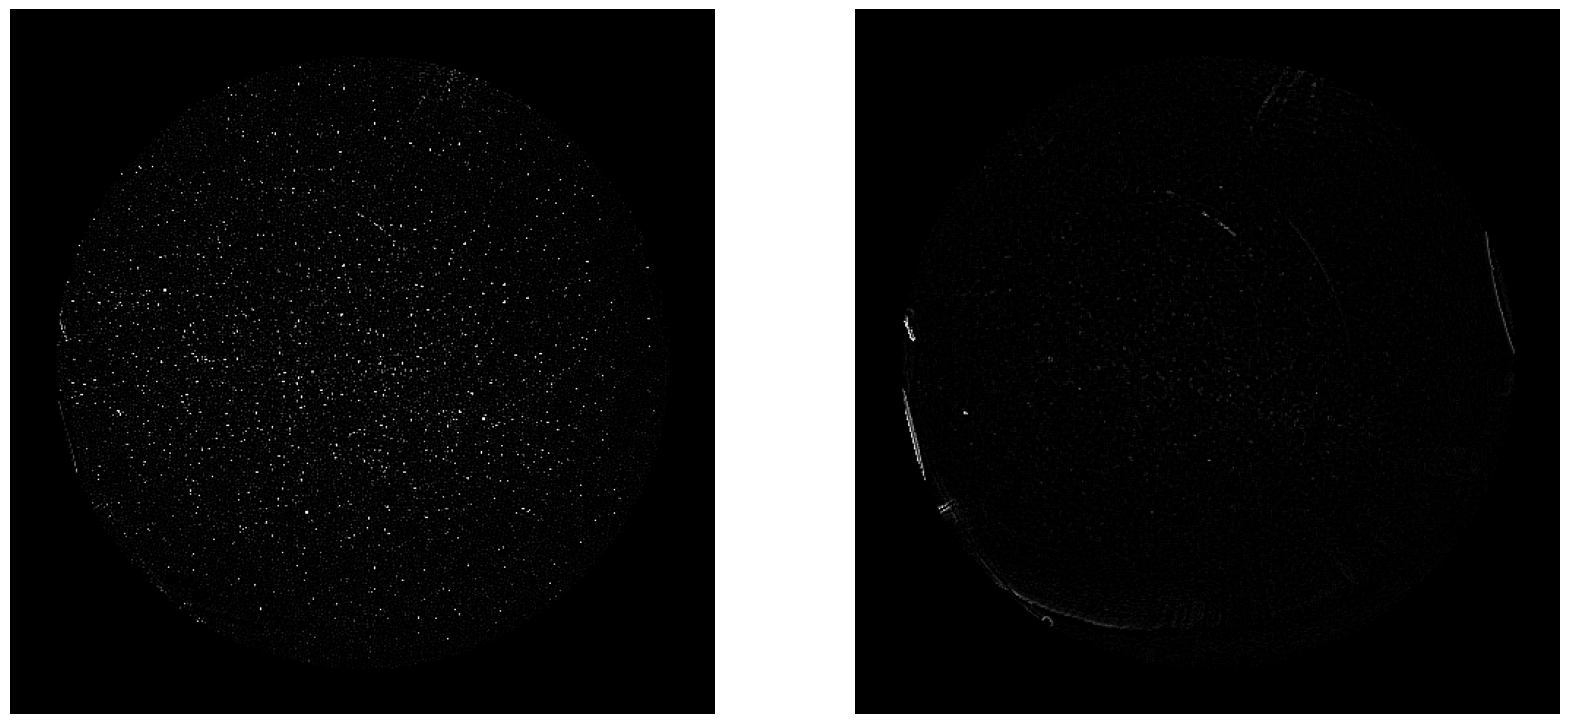

In [8]:
mask = np.zeros(im_gray.shape[:2], dtype="uint8")
cv2.circle(mask, (int(im_gray.shape[0]/2), int(im_gray.shape[0]/2)), 210, 255, -1)
# mask = cv2.blur(mask, (25, 25))
features = cv2.bitwise_and(features, features, mask=mask)
defect_features = cv2.bitwise_and(defect_features, defect_features, mask=mask)

display_two_images(features, defect_features)

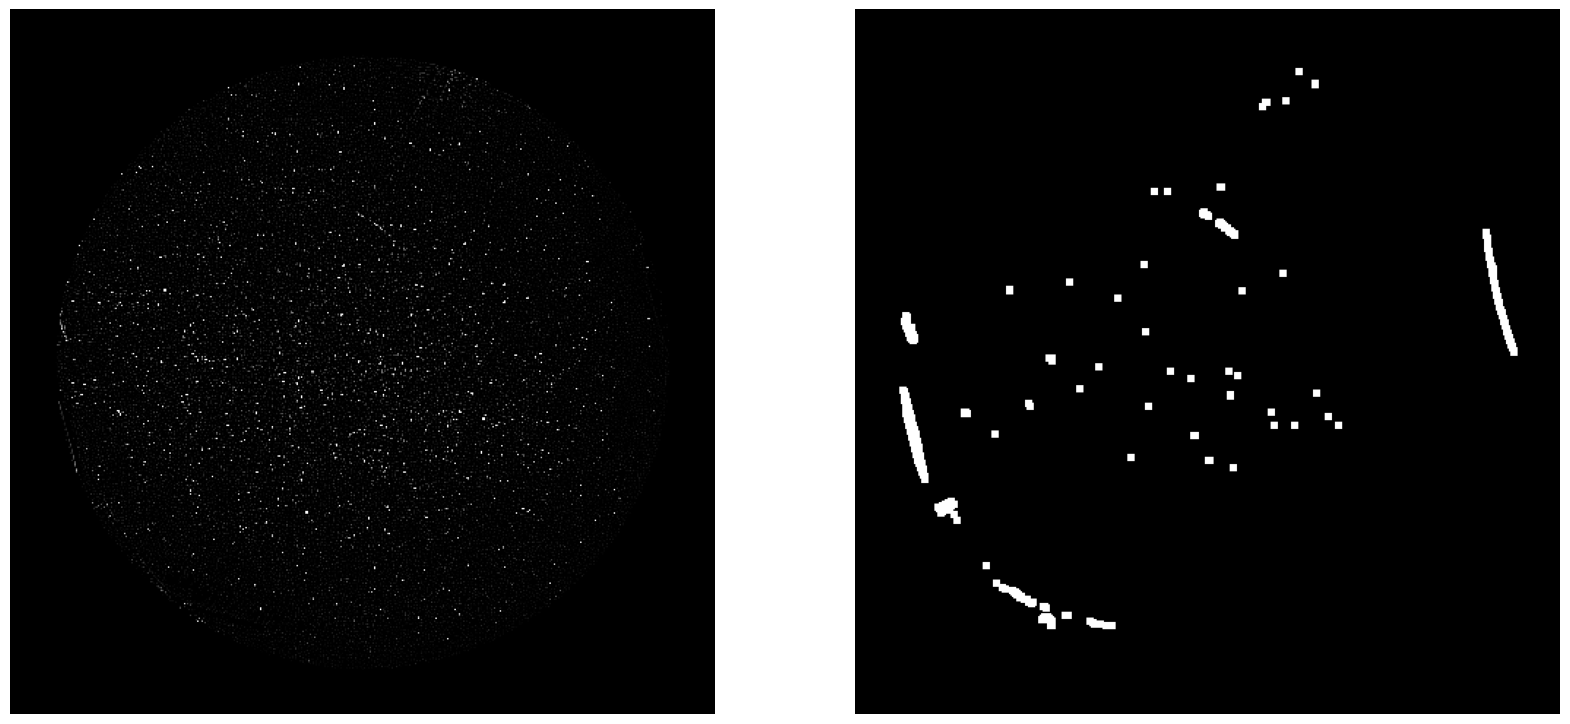

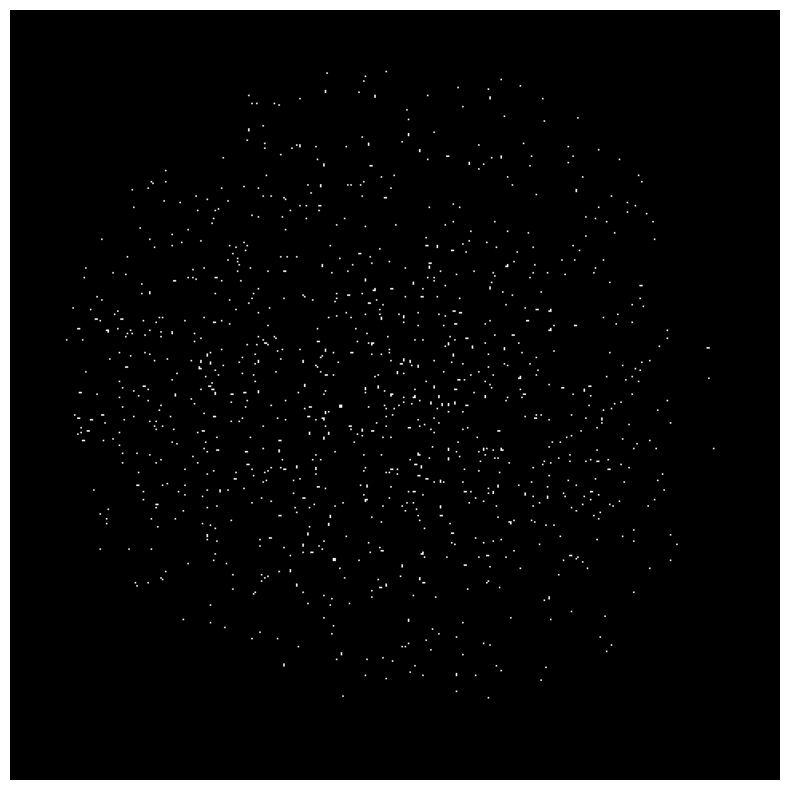

In [9]:
_, defect_features_threshold = cv2.threshold(defect_features, 50, 255, cv2.THRESH_BINARY)
defect_features_threshold = cv2.dilate(defect_features_threshold, np.ones((5, 5)), iterations=1)
# defect_features_threshold_median = cv2.medianBlur(defect_features_threshold, 3)

display_two_images(features, defect_features_threshold)

features = cv2.subtract(features, defect_features_threshold)

_, features = cv2.threshold(features, 100, 255, cv2.THRESH_BINARY)

# features = cv2.dilate(features, np.ones((3, 3)), iterations=1)
# features = cv2.medianBlur(features, 3)

display_image(features)

## Finding stars

### First calculating entropy (in simplest terms, how spread out the found stars are)

In [10]:
def spatial_entropy(stars, split_size):
    total = np.sum(stars != 0)

    if total == 0:
        return 0.0

    counts = [
        np.count_nonzero(stars[x:x+split_size, y:y+split_size])
        for x in range(0, stars.shape[0], split_size)
        for y in range(0, stars.shape[1], split_size)
    ]

    counts = np.asarray(counts, dtype=float)
    p = counts[counts > 0] / total

    H = -np.sum(p * np.log2(p))

    return H


Spatial entropy: 681.32
Stars: 995


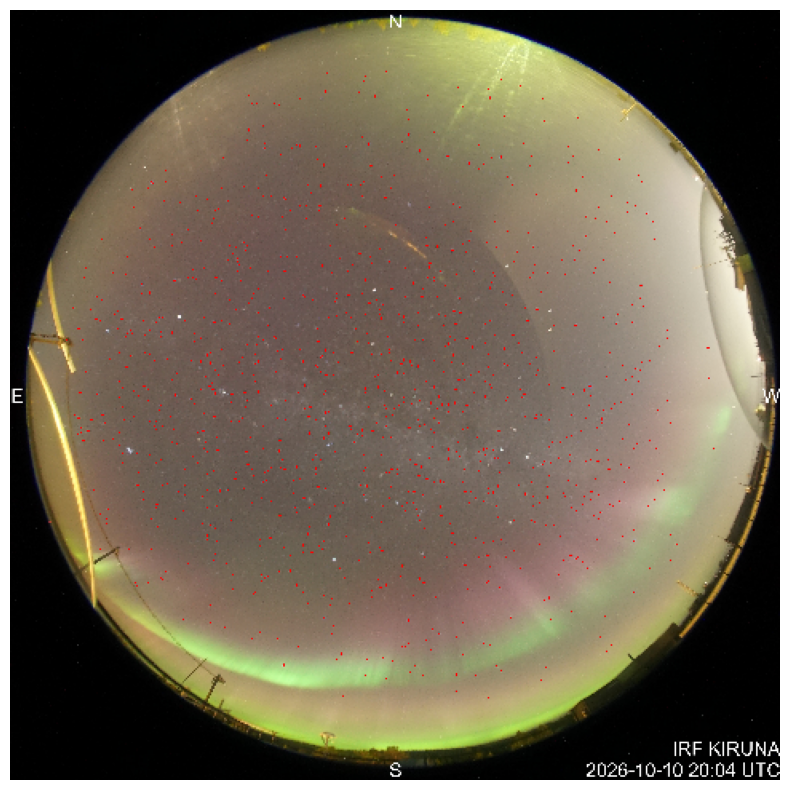

In [11]:
binary = (features > 0).astype(np.uint8)

num_labels, labels, stats, centroids = \
    cv2.connectedComponentsWithStats(binary, connectivity=8)

max_area = 2

# Build a mask containing only components with 1–3 pixels
stars = np.zeros_like(binary)
num_stars = 0

for i in range(1, num_labels):  # Skip background
    area = stats[i, cv2.CC_STAT_AREA]
    if area <= max_area:
        stars[labels == i] = 1
        num_stars += 1

overlay = im.copy()
overlay[stars > 0] = (0, 0, 255)

print(f'Spatial entropy: {spatial_entropy(stars, 32) * 100:.2f}')

print(f'Stars: {num_stars}')

display_image(overlay)

# The final function

In [ ]:
def star_recgognition(img, size, mask_size):
    img = cv2.resize(img, 
            (size,size),
            interpolation=cv2.INTER_NEAREST)

    # B/W conversion
    im_gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Making a defect image (reflections and unwanted elements in the picture)
    blur = cv2.medianBlur(im_gray, 3)

    # "Killing" the stars, while leaving the defects slightly blurred
    subtracted = cv2.subtract(im_gray, blur)

    # Laplacian sharpening kernel, does surprisingly well on extracting stars from the aurora
    kernel = np.asarray([
        [-1, -1, -1],
        [-1, 8, -1],
        [-1, -1, -1]
    ])

    features = cv2.filter2D(subtracted, ddepth=-1, kernel=kernel, anchor=(-1, -1), delta=0, borderType=cv2.BORDER_DEFAULT)
    defect_features = cv2.filter2D(blur, ddepth=-1, kernel=kernel, anchor=(-1, -1), delta=0, borderType=cv2.BORDER_DEFAULT)

    # Masking only the central circle of the image
    mask = np.zeros(im_gray.shape[:2], dtype="uint8")
    cv2.circle(mask, (int(im_gray.shape[0]/2), int(im_gray.shape[0]/2)), mask_size, 255, -1)

    features = cv2.bitwise_and(features, features, mask=mask)
    defect_features = cv2.bitwise_and(defect_features, defect_features, mask=mask)

    # Final subtraction to kill of any residual unwanted features
    _, defect_features_threshold = cv2.threshold(defect_features, 50, 255, cv2.THRESH_BINARY)
    defect_features_threshold = cv2.dilate(defect_features_threshold, np.ones((5, 5)), iterations=1)

    features = cv2.subtract(features, defect_features_threshold)

    _, features = cv2.threshold(features, 100, 255, cv2.THRESH_BINARY)

    binary = (features > 0).astype(np.uint8)

    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)

    max_area = 2

    # Build a mask containing only components with 1–3 pixels
    stars = np.zeros_like(binary)
    num_stars = 0

    for i in range(1, num_labels):  # Skip background
        area = stats[i, cv2.CC_STAT_AREA]
        if area <= max_area:
            stars[labels == i] = 1
            num_stars += 1

    return stars, num_stars

findfont: Failed to find font weight normal for Lucida Grande, now using 500.
findfont: Failed to find font weight normal for Lucida Grande, now using 500.
findfont: Failed to find font weight normal for Lucida Grande, now using 500.


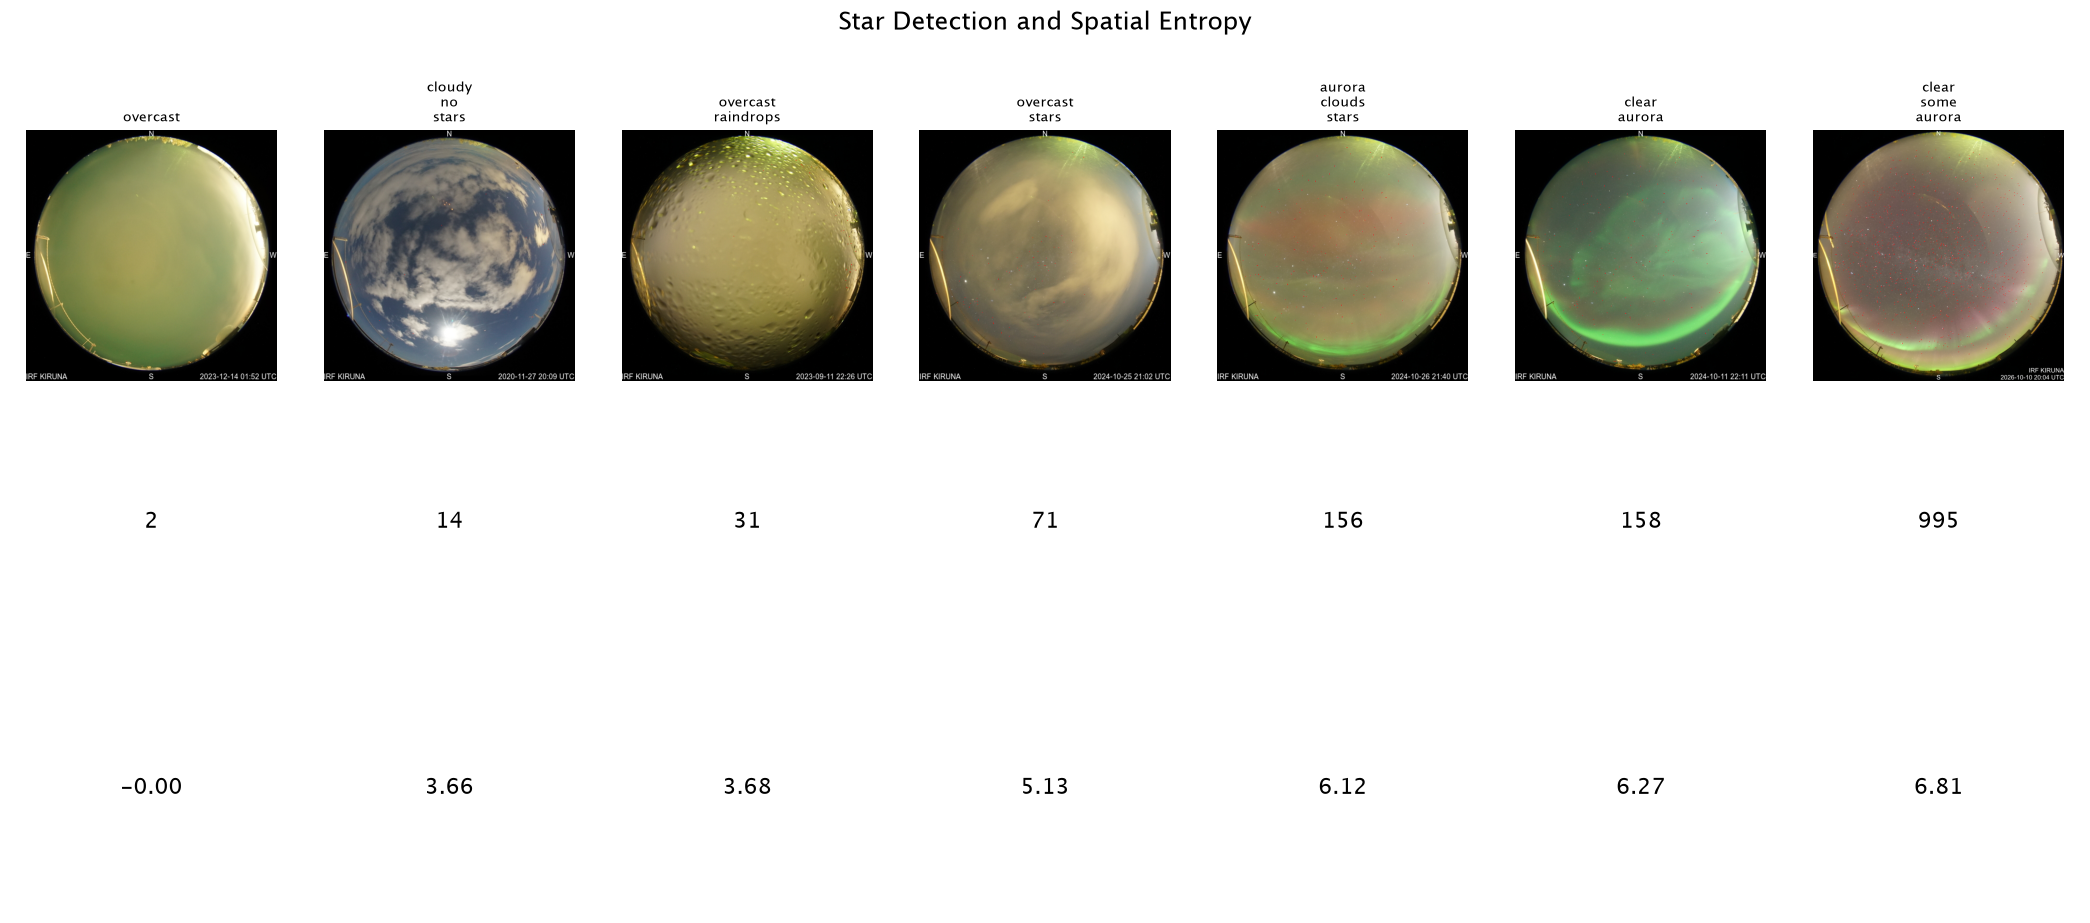

In [ ]:
results = []

for name, im in images.items():
    stars, num_stars = star_recgognition(im, 482, 210)
    H = spatial_entropy(stars, 32)

    stars = cv2.resize(
        stars,
        (im.shape[1], im.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    overlay = im.copy()
    overlay[stars > 0] = (0, 0, 255)
    overlay = cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB)

    results.append({
        "name": name,
        "image": overlay,
        "num_stars": num_stars,
        "entropy": H
    })

# Sort by entropy, lowest to highest
results.sort(key=lambda x: x["entropy"])

# Plot the 7 x 3 table
fig, axes = plt.subplots(3, 7, figsize=(21, 9))
fig.suptitle("Star Detection and Spatial Entropy", fontsize=18, y=1.02)

for col, result in enumerate(results):
    # Row 1: Image
    axes[0, col].imshow(result["image"])
    axes[0, col].set_title(
        result["name"].replace("_", "\n"), fontsize=10
    )
    axes[0, col].axis("off")

    # Row 2: Number of stars
    axes[1, col].text(
        0.5, 0.5, f'{result["num_stars"]:,}',
        ha="center", va="center", fontsize=16
    )
    axes[1, col].axis("off")

    # Row 3: Entropy
    axes[2, col].text(
        0.5, 0.5, f'{result["entropy"]:.2f}',
        ha="center", va="center", fontsize=16
    )
    axes[2, col].axis("off")

axes[0, 0].set_ylabel("Image", fontsize=13, labelpad=12)
axes[1, 0].set_ylabel("Number of stars", fontsize=13, labelpad=12)
axes[2, 0].set_ylabel("Entropy (bits)", fontsize=13, labelpad=12)

plt.tight_layout()
plt.show()
